# ==================================================================================
**Carrera de Ingeniería de Sistemas — Universidad Franz Tamayo**

**Asignatura:** MINERÍA DE DATOS  ·  **Docente:** Enrique Alejandro Laurel Cossio  ·  Octubre 2026

**Proyecto:** Sistema de recomendación de películas — MovieLens 1M

## TEMA: ÁRBOL DE DECISIÓN (CLASIFICACIÓN) — ¿Le gustará la película al usuario?
# ==================================================================================

Este cuaderno resuelve **el mismo problema que la regresión logística** ([`07_regresion_logistica`](../07_regresion_logistica/regresion_logistica.ipynb)),
con el mismo target, las mismas variables y la misma partición, pero con un **árbol de decisión**. Así los dos modelos se pueden comparar directamente.

Responde, en orden, las 9 preguntas de la primera iteración:

| # | Pregunta | Sección |
|---|---|---|
| 1 | Identificar mi métrica y su valor | 4.1.1 |
| 2 | Identificar la variable que calcula mi métrica | 4.1.2 |
| 3 | Definir mi target (relacionado con la métrica principal) | 4.1.3 |
| 4 | Escoger las variables explicativas | 4.1.4 |
| 5 | Partición de datos en train y test | 4.1.5 |
| 6 | Entrenar el modelo | 4.2 |
| 7 | Evaluación en datos de train | 4.3.2 |
| 8 | Evaluación en datos de test | 4.3.3 |
| 9 | Resultados del modelo de mi primera iteración | 4.4 |

# 1. LIBRERÍAS Y FUNCIONES

In [1]:
# Cargamos Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split, KFold
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, roc_curve)

In [2]:
# Función: pone la proporción encima de cada barra (igual que en el ejemplo de clase)
def poner_proporciones(ax, total):
    for p in ax.patches:
        height = p.get_height()
        ax.text(p.get_x() + p.get_width() / 2.,
                height + total * 0.005,
                '{:1.2f}'.format(height / total),
                ha="center")


# Función: calcula todas las métricas de clasificación de una vez
def metricas_clasificacion(y_real, y_prob, umbral):
    y_clase = (y_prob > umbral).astype(int)
    return {
        'Exactitud': accuracy_score(y_real, y_clase),
        'Precisión': precision_score(y_real, y_clase),
        'Recall': recall_score(y_real, y_clase),
        'F1-Score': f1_score(y_real, y_clase),
        'AUC': roc_auc_score(y_real, y_prob),
    }


# Función: muestra la matriz de confusión con nombres en español
def tabla_confusion(y_real, y_prob, umbral):
    y_clase = (y_prob > umbral).astype(int)
    mc = confusion_matrix(y_real, y_clase)
    return pd.DataFrame(mc,
                        index=['Real: No me gusta', 'Real: Me gusta'],
                        columns=['Modelo: No me gusta', 'Modelo: Me gusta'])

# 2. PARÁMETROS

In [3]:
RUTA_DATOS = '../03_preparacion_datos/datos/'

ESTRELLAS_ME_GUSTA = 4       # rating >= 4 (4 y 5) -> Me gusta ; rating 1, 2, 3 -> No me gusta
TEST_SIZE = 0.2              # 80% train / 20% test (mismo hold-out del proyecto)
RANDOM_STATE = 777           # misma semilla que el ejemplo de clase y que la regresión logística
UMBRAL = 0.5                 # probabilidad a partir de la cual el modelo dice "Me gusta"
K_SUAVIZADO = 10             # votos "ficticios" con la tasa global para usuarios/películas con pocos votos
N_PARTICIONES = 5            # particiones para calcular las variables de historial en train (sección 4.1.5)

PROFUNDIDADES = [2, 3, 4, 5, 6, 8, 10, 12, 15]   # profundidades que se prueban (sección 4.2)
MIN_MUESTRAS_HOJA = 100      # cada hoja necesita al menos 100 calificaciones (evita reglas con pocos casos)

COLOR_NO_GUSTA = '#eb6834'   # naranja
COLOR_GUSTA = '#2a78d6'      # azul
COLORES_TARGET = [COLOR_NO_GUSTA, COLOR_GUSTA]

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

# 3. DATOS

In [4]:
# cargamos datos (salida de la fase de preparación del proyecto)
ratings_df = pd.read_csv(RUTA_DATOS + 'datos_limpios.csv', sep=',')
usuarios_df = pd.read_csv(RUTA_DATOS + 'usuarios.csv', sep=',')

print('calificaciones:', ratings_df.shape)
print('usuarios      :', usuarios_df.shape)

calificaciones: (1000209, 9)
usuarios      : (6040, 5)


In [5]:
# unimos cada calificación con los datos del usuario que la dio
movies_df = ratings_df.merge(usuarios_df, on='userId', how='left')

print(movies_df.shape)
movies_df.head(3)

(1000209, 13)


,userId,movieId,rating,timestamp,fecha,anio,title,genres,anio_estreno,gender,age,occupation,zip
0,1,1193,5.0,978300760,2000-12-31 22:12:40,2000,One Flew Over the Cuckoo's Nest (1975),Drama,1975,F,1,10,48067
1,1,661,3.0,978302109,2000-12-31 22:35:09,2000,James and the Giant Peach (1996),Animation|Children's|Musical,1996,F,1,10,48067
2,1,914,3.0,978301968,2000-12-31 22:32:48,2000,My Fair Lady (1964),Musical|Romance,1964,F,1,10,48067


# 4. PROCESO

## 4.1. ENTENDIMIENTO Y PREPARACIÓN DE DATOS

In [6]:
# ¿hay datos faltantes?
movies_df.isna().sum()

userId          0
movieId         0
rating          0
timestamp       0
fecha           0
anio            0
title           0
genres          0
anio_estreno    0
gender          0
age             0
occupation      0
zip             0
dtype: int64

### 4.1.1. Pregunta 1 — Identificar mi métrica y su valor
### 4.1.2. Pregunta 2 — Identificar la variable que calcula mi métrica

Igual que en la regresión logística, la variable que expresa la preferencia del usuario es **`rating`** (1 a 5 estrellas) y la métrica es:

$$\text{Tasa de Me gusta} = \frac{\text{calificaciones con } rating \geq 4}{\text{total de calificaciones}}$$

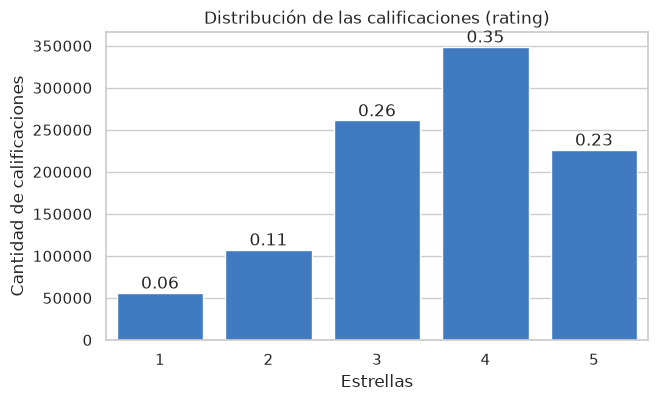

Variable que calcula la métrica : rating
Métrica principal               : Tasa de Me gusta (rating >= 4)
Valor de la métrica             : 57.52%


In [7]:
# una copia a los datos
df = movies_df.copy()

# MÉTRICA PRINCIPAL
tasa_me_gusta = (df['rating'] >= ESTRELLAS_ME_GUSTA).mean()

plt.figure(figsize=(7, 4))
ax = sns.countplot(x=df['rating'].astype(int), color=COLOR_GUSTA)
poner_proporciones(ax, float(len(df)))
plt.title('Distribución de las calificaciones (rating)')
plt.xlabel('Estrellas')
plt.ylabel('Cantidad de calificaciones')
plt.show()

print('Variable que calcula la métrica : rating')
print('Métrica principal               : Tasa de Me gusta (rating >= 4)')
print('Valor de la métrica             : {:.2%}'.format(tasa_me_gusta))

### 4.1.3. Pregunta 3 — Definir mi target

| rating | le_gusta (target) | Significado |
|---|---|---|
| 1, 2, 3 | **0** | No me gusta |
| 4, 5 | **1** | Me gusta |

El promedio de `le_gusta` **es exactamente la métrica principal**.

In [8]:
# creamos el target
df['le_gusta'] = (df['rating'] >= ESTRELLAS_ME_GUSTA).astype(int)

# comprobamos que cada estrella cae en la clase correcta
pd.crosstab(df['rating'], df['le_gusta'])

le_gusta,0,1
rating,,
1.0,56174,0
2.0,107557,0
3.0,261197,0
4.0,0,348971
5.0,0,226310


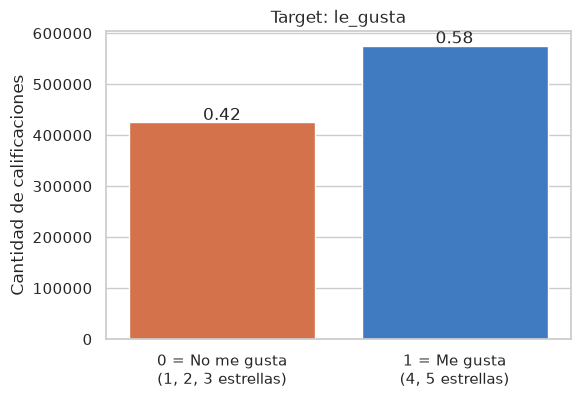

Promedio del target = 57.52%  (igual a la métrica principal)


In [9]:
# proporción de casos Me gusta / No me gusta
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='le_gusta', data=df, hue='le_gusta', palette=COLORES_TARGET, legend=False)
poner_proporciones(ax, float(len(df)))
ax.set_xticks([0, 1])
ax.set_xticklabels(['0 = No me gusta\n(1, 2, 3 estrellas)', '1 = Me gusta\n(4, 5 estrellas)'])
plt.title('Target: le_gusta')
plt.xlabel('')
plt.ylabel('Cantidad de calificaciones')
plt.show()

print('Promedio del target = {:.2%}  (igual a la métrica principal)'.format(df['le_gusta'].mean()))

### 4.1.4. Pregunta 4 — Escoger las variables explicativas

Se usan **las mismas 23 variables que en la regresión logística**, para que la comparación sea justa.
Los gráficos que justifican cada una están en la sección 4.1.4 de [`regresion_logistica.ipynb`](../07_regresion_logistica/regresion_logistica.ipynb).

| Grupo | Variable | Por qué |
|---|---|---|
| Usuario | `gender_M` (1 = hombre, 0 = mujer) | Las mujeres dan un poco más de Me gusta |
| Usuario | `age` | A más edad, mayor tasa de Me gusta |
| Película | `anio_estreno` | Las películas antiguas reciben más Me gusta que las recientes |
| Película | `genero_*` (18 dummies) | Film-Noir, Documentary y War gustan más; Horror, Children's y Fantasy menos |
| Historial | `tasa_usuario` | Qué tan "generoso" es el usuario: su propia tasa de Me gusta |
| Historial | `tasa_pelicula` | Qué tan bien valorada está la película por los demás |

Un árbol **no necesita escalar ni normalizar** las variables: solo compara cada variable con un punto de corte.

In [10]:
# variable dummy de sexo
df['gender_M'] = (df['gender'] == 'M').astype(int)

# dummies de género de película (una película puede tener varios géneros)
generos = df['genres'].str.get_dummies(sep='|')
generos.columns = ['genero_' + c.replace("'", '').replace('-', '_') for c in generos.columns]
df = pd.concat([df, generos.astype(int)], axis=1)

print(df.shape)

(1000209, 33)


### 4.1.5. Pregunta 5 — Partición de datos en train y test

- **80% train / 20% test**, con `random_state=777` y `stratify=y`, exactamente igual que en la regresión logística.
- El test **no se toca** hasta la sección 4.3.3.

In [11]:
# seleccionamos variables explicativas y variable dependiente
columnas_generos = list(generos.columns)
variables_base = ['gender_M', 'age', 'anio_estreno'] + columnas_generos

X = df[['userId', 'movieId'] + variables_base]   # userId y movieId solo para calcular el historial
y = df['le_gusta']                               # target variable

# Dividir los datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

X_train = X_train.copy()
X_test = X_test.copy()

print('tamaño train', X_train.shape)
print('tamaño de test', X_test.shape)
print('tasa Me gusta train: {:.2%}'.format(y_train.mean()))
print('tasa Me gusta test : {:.2%}'.format(y_test.mean()))

tamaño train (800167, 23)
tamaño de test (200042, 23)
tasa Me gusta train: 57.52%
tasa Me gusta test : 57.52%


**Variables de historial (calculadas solo con train)**

Igual que en la regresión logística, la tasa de cada usuario y de cada película se suaviza con `K_SUAVIZADO` votos ficticios:

$$\text{tasa} = \frac{s + K \cdot \text{tasa global}}{n + K}$$

**Diferencia con la regresión logística: cómo se calcula en train.**
La regresión logística resta la propia calificación de la fila (`s - y`, `n - 1`). Con un árbol eso **no sirve**:
dentro de un mismo usuario, las filas *Me gusta* quedan con una tasa un poquito **menor** que las *No me gusta*,
y un árbol profundo aprende esa pista falsa (en train parece mejorar, pero en test empeora).

Por eso aquí se usan **5 particiones de train**: la tasa de cada fila se calcula con las otras 4 particiones,
así ninguna fila ve su propia respuesta ni deja una pista. **En test** se usan los conteos de todo train.

In [12]:
tasa_global_train = y_train.mean()
entrenamiento = X_train[['userId', 'movieId']].assign(le_gusta=y_train)

# a cada fila de train le asignamos una de las 5 particiones
particion = np.zeros(len(X_train), dtype=int)
kfold = KFold(n_splits=N_PARTICIONES, shuffle=True, random_state=RANDOM_STATE)
for numero, (_, filas) in enumerate(kfold.split(X_train)):
    particion[filas] = numero


def tasa_suavizada(claves, conteo):
    n = claves.map(conteo['n']).fillna(0)
    s = claves.map(conteo['s']).fillna(0)
    return (s + K_SUAVIZADO * tasa_global_train) / (n + K_SUAVIZADO)


for clave, nombre in [('userId', 'tasa_usuario'), ('movieId', 'tasa_pelicula')]:
    # train: cada partición se calcula con las otras 4
    valores = np.zeros(len(X_train))
    for numero in range(N_PARTICIONES):
        en_particion = particion == numero
        conteo = entrenamiento[~en_particion].groupby(clave)['le_gusta'].agg(n='count', s='sum')
        valores[en_particion] = tasa_suavizada(X_train.loc[en_particion, clave], conteo).to_numpy()
    X_train[nombre] = valores

    # test: con lo aprendido en todo train
    conteo = entrenamiento.groupby(clave)['le_gusta'].agg(n='count', s='sum')
    X_test[nombre] = tasa_suavizada(X_test[clave], conteo)

variables_explicativas = ['tasa_usuario', 'tasa_pelicula'] + variables_base
X_train = X_train[variables_explicativas]
X_test = X_test[variables_explicativas]

print('variables explicativas:', len(variables_explicativas))
X_train[['tasa_usuario', 'tasa_pelicula', 'age', 'anio_estreno']].describe()

variables explicativas: 23


,tasa_usuario,tasa_pelicula,age,anio_estreno
count,800167.000000,800167.000000,800167.000000,800167.000000
mean,0.571678,0.579670,29.737549,1986.690895
std,0.161511,0.194038,11.754684,14.358987
min,0.075266,0.051418,1.000000,1919.000000
25%,0.462934,0.442138,25.000000,1982.000000
50%,0.585344,0.609722,25.000000,1992.000000
75%,0.692093,0.735478,35.000000,1997.000000
max,0.949424,0.934506,56.000000,2000.000000


## 4.2. MODELO
### Pregunta 6 — Entrenar el modelo

`DecisionTreeClassifier` de scikit-learn. Lo más importante es la **profundidad** (`max_depth`):

- Muy poca → el árbol es demasiado simple y no aprende (subajuste).
- Demasiada → el árbol memoriza train y falla con datos nuevos (sobreajuste).

Para elegirla **sin mirar el test**, se separa un 20% de train como **validación**, se entrenan árboles de varias profundidades
y se elige la que mejor AUC tiene en validación. Después se reentrena con todo train.

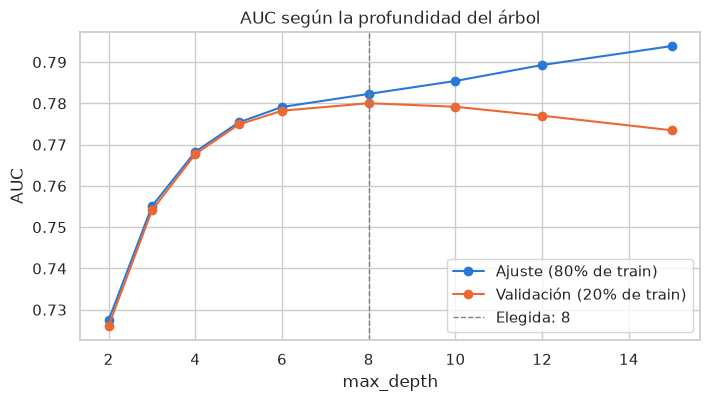

Profundidad elegida: 8


,AUC ajuste,AUC validación
profundidad,,
2,0.7274,0.7261
3,0.7551,0.7541
4,0.7683,0.7677
5,0.7754,0.7749
6,0.7791,0.7782
8,0.7823,0.7800
10,0.7854,0.7792
12,0.7893,0.7770
15,0.7939,0.7735


In [13]:
# validación: 20% de train (el test sigue sin usarse)
X_ajuste, X_valid, y_ajuste, y_valid = train_test_split(
    X_train, y_train, test_size=0.2, random_state=RANDOM_STATE, stratify=y_train)

curva = []
for profundidad in PROFUNDIDADES:
    arbol_prueba = DecisionTreeClassifier(max_depth=profundidad, min_samples_leaf=MIN_MUESTRAS_HOJA,
                                          random_state=RANDOM_STATE).fit(X_ajuste, y_ajuste)
    curva.append({'profundidad': profundidad,
                  'AUC ajuste': roc_auc_score(y_ajuste, arbol_prueba.predict_proba(X_ajuste)[:, 1]),
                  'AUC validación': roc_auc_score(y_valid, arbol_prueba.predict_proba(X_valid)[:, 1])})
curva = pd.DataFrame(curva).set_index('profundidad')
mejor_profundidad = int(curva['AUC validación'].idxmax())

plt.figure(figsize=(8, 4))
plt.plot(curva.index, curva['AUC ajuste'], marker='o', color=COLOR_GUSTA, label='Ajuste (80% de train)')
plt.plot(curva.index, curva['AUC validación'], marker='o', color=COLOR_NO_GUSTA, label='Validación (20% de train)')
plt.axvline(mejor_profundidad, color='gray', linestyle='--', linewidth=1, label=f'Elegida: {mejor_profundidad}')
plt.title('AUC según la profundidad del árbol')
plt.xlabel('max_depth')
plt.ylabel('AUC')
plt.legend()
plt.show()

print('Profundidad elegida:', mejor_profundidad)
curva.round(4)

In [14]:
# Ajusta el árbol final con todo train y la profundidad elegida
modelo_arbol = DecisionTreeClassifier(max_depth=mejor_profundidad, min_samples_leaf=MIN_MUESTRAS_HOJA,
                                      random_state=RANDOM_STATE)
modelo_arbol.fit(X_train, y_train)

print(modelo_arbol)
print('hojas del árbol:', modelo_arbol.get_n_leaves())

DecisionTreeClassifier(max_depth=8, min_samples_leaf=100, random_state=777)
hojas del árbol: 255


## 4.3. EVALUACIÓN

### 4.3.1. Métricas

- **TP** (Verdaderos Positivos): le gustó y el modelo dijo Me gusta.
- **TN** (Verdaderos Negativos): no le gustó y el modelo dijo No me gusta.
- **FP** (Falsos Positivos): no le gustó pero el modelo dijo Me gusta → *recomendamos una película mala*.
- **FN** (Falsos Negativos): le gustó pero el modelo dijo No me gusta → *dejamos de recomendar una buena*.

$$\text{Exactitud} = \frac{TP + TN}{TP + TN + FP + FN} \qquad \text{Precisión} = \frac{TP}{TP + FP} \qquad \text{Recall} = \frac{TP}{TP + FN}$$

$$F1 = 2 \cdot \frac{\text{Precisión} \cdot \text{Recall}}{\text{Precisión} + \text{Recall}}$$

**AUC**: capacidad del modelo para separar Me gusta de No me gusta (0,5 = azar, 1 = perfecto).

**Línea base:** un modelo "tonto" que dice *Me gusta* a todo acierta la tasa global (~57,5%).

### 4.3.2. Pregunta 7 — Evaluación en datos de train

In [15]:
# probabilidad de Me gusta = proporción de Me gusta en la hoja a la que llega cada calificación
y_pred_train = modelo_arbol.predict_proba(X_train)[:, 1]

metricas_train = metricas_clasificacion(y_train, y_pred_train, UMBRAL)
for nombre, valor in metricas_train.items():
    print('{:<10}: {:.4f}'.format(nombre, valor))

print('\nLínea base (decir Me gusta a todo): {:.4f}'.format(y_train.mean()))

Exactitud : 0.7192
Precisión : 0.7280
Recall    : 0.8172
F1-Score  : 0.7700
AUC       : 0.7820

Línea base (decir Me gusta a todo): 0.5752


In [16]:
print('Matriz de confusión (train):')
tabla_confusion(y_train, y_pred_train, UMBRAL)

Matriz de confusión (train):


,Modelo: No me gusta,Modelo: Me gusta
Real: No me gusta,199425,140517
Real: Me gusta,84145,376080


### 4.3.3. Pregunta 8 — Evaluación en datos de test

Estos datos **no se usaron para entrenar ni para elegir la profundidad**.

In [17]:
y_pred = modelo_arbol.predict_proba(X_test)[:, 1]

metricas_test = metricas_clasificacion(y_test, y_pred, UMBRAL)
for nombre, valor in metricas_test.items():
    print('{:<10}: {:.4f}'.format(nombre, valor))

print('\nLínea base (decir Me gusta a todo): {:.4f}'.format(y_test.mean()))

Exactitud : 0.7200
Precisión : 0.7282
Recall    : 0.8189
F1-Score  : 0.7709
AUC       : 0.7815

Línea base (decir Me gusta a todo): 0.5752


In [18]:
print('Matriz de confusión (test):')
tabla_confusion(y_test, y_pred, UMBRAL)

Matriz de confusión (test):


,Modelo: No me gusta,Modelo: Me gusta
Real: No me gusta,49818,35168
Real: Me gusta,20841,94215


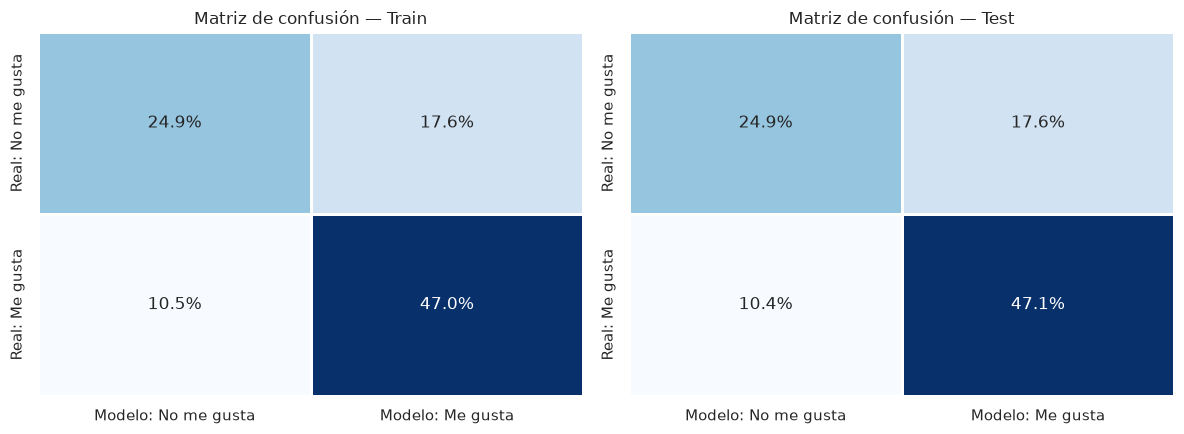

In [19]:
# matrices de confusión en porcentaje: train vs test
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (titulo, y_real, y_prob) in zip(axes, [('Train', y_train, y_pred_train), ('Test', y_test, y_pred)]):
    mc = tabla_confusion(y_real, y_prob, UMBRAL)
    sns.heatmap(mc / mc.values.sum(), annot=True, fmt='.1%', cmap='Blues', cbar=False, ax=ax,
                linewidths=2, linecolor='white')
    ax.set_title('Matriz de confusión — ' + titulo)
plt.tight_layout()
plt.show()

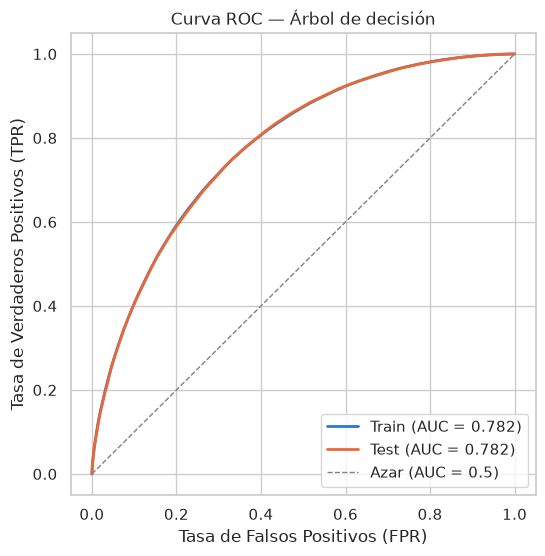

In [20]:
# curva ROC: train vs test
plt.figure(figsize=(6, 6))
for titulo, y_real, y_prob, color in [('Train', y_train, y_pred_train, COLOR_GUSTA),
                                      ('Test', y_test, y_pred, COLOR_NO_GUSTA)]:
    fpr, tpr, _ = roc_curve(y_real, y_prob)
    plt.plot(fpr, tpr, color=color, linewidth=2,
             label='{} (AUC = {:.3f})'.format(titulo, roc_auc_score(y_real, y_prob)))
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1, label='Azar (AUC = 0.5)')
plt.title('Curva ROC — Árbol de decisión')
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.legend(loc='lower right')
plt.show()

### 4.3.4. ¿Cómo decide el árbol?

Lo que distingue al árbol de la regresión logística es que **sus reglas se pueden leer**.
Se dibujan los tres primeros niveles; cada caja muestra la regla, cuántas calificaciones llegan (`samples`)
y la proporción de No me gusta / Me gusta (`value`).

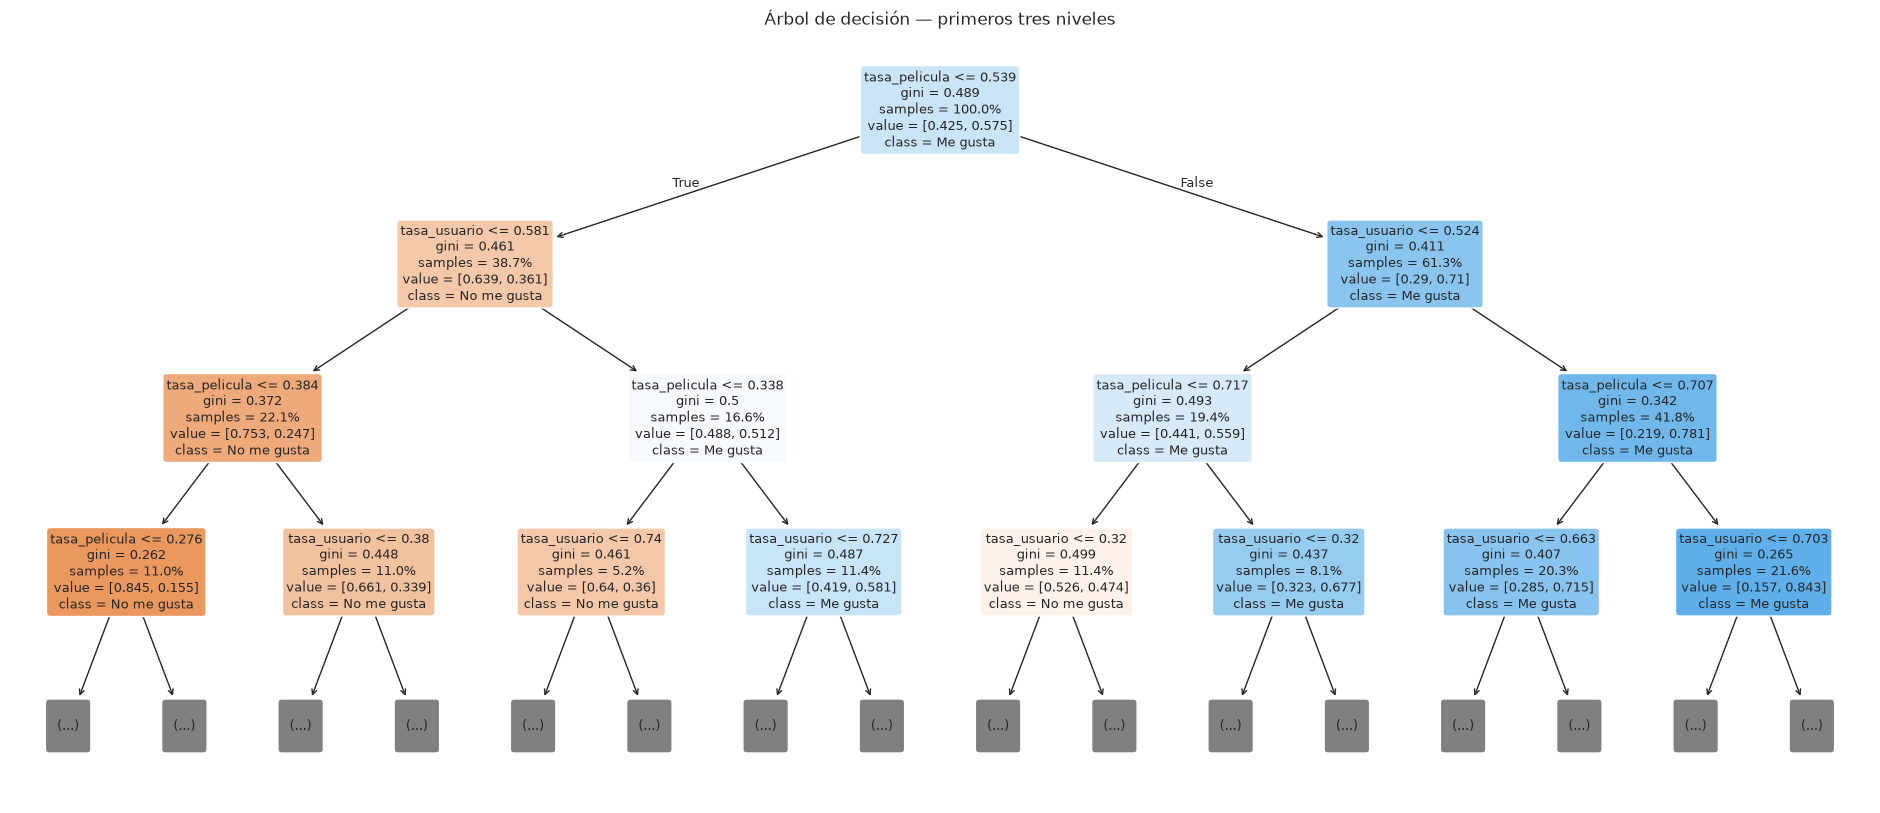

In [21]:
fig, ax = plt.subplots(figsize=(24, 10))
plot_tree(modelo_arbol, feature_names=variables_explicativas, class_names=['No me gusta', 'Me gusta'],
          filled=True, rounded=True, proportion=True, max_depth=3, fontsize=9, ax=ax)
ax.set_title('Árbol de decisión — primeros tres niveles')
plt.show()

In [22]:
# reglas de los primeros niveles en texto
print(export_text(modelo_arbol, feature_names=variables_explicativas, max_depth=2, decimals=3))

|--- tasa_pelicula <= 0.539
|   |--- tasa_usuario <= 0.581
|   |   |--- tasa_pelicula <= 0.384
|   |   |   |--- truncated branch of depth 6
|   |   |--- tasa_pelicula >  0.384
|   |   |   |--- truncated branch of depth 6
|   |--- tasa_usuario >  0.581
|   |   |--- tasa_pelicula <= 0.338
|   |   |   |--- truncated branch of depth 6
|   |   |--- tasa_pelicula >  0.338
|   |   |   |--- truncated branch of depth 6
|--- tasa_pelicula >  0.539
|   |--- tasa_usuario <= 0.524
|   |   |--- tasa_pelicula <= 0.717
|   |   |   |--- truncated branch of depth 6
|   |   |--- tasa_pelicula >  0.717
|   |   |   |--- truncated branch of depth 6
|   |--- tasa_usuario >  0.524
|   |   |--- tasa_pelicula <= 0.707
|   |   |   |--- truncated branch of depth 6
|   |   |--- tasa_pelicula >  0.707
|   |   |   |--- truncated branch of depth 6



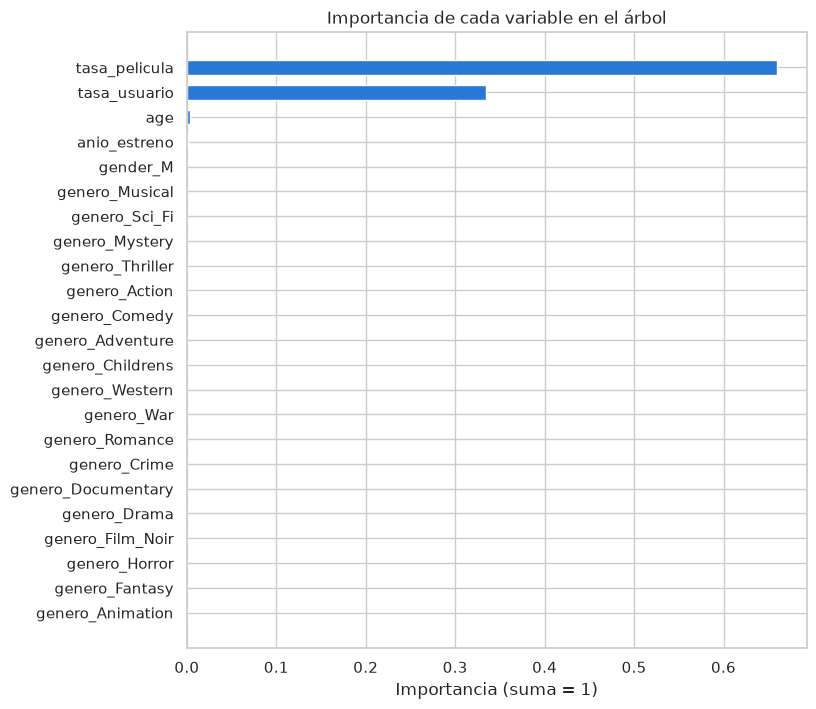

tasa_pelicula     0.6602
tasa_usuario      0.3341
age               0.0033
anio_estreno      0.0015
gender_M          0.0006
genero_Musical    0.0001
genero_Sci_Fi     0.0001
genero_Mystery    0.0000
dtype: float64

In [23]:
# importancia de cada variable: cuánto ayuda a separar las clases en las divisiones del árbol
importancia = pd.Series(modelo_arbol.feature_importances_, index=variables_explicativas).sort_values()

plt.figure(figsize=(8, 8))
plt.barh(importancia.index, importancia.values, color=COLOR_GUSTA, height=0.6)
plt.title('Importancia de cada variable en el árbol')
plt.xlabel('Importancia (suma = 1)')
plt.show()

importancia.sort_values(ascending=False).head(8).round(4)

## 4.4. Pregunta 9 — Resultados del modelo de mi primera iteración

Se compara el árbol con la línea base y con una **regresión logística entrenada con las mismas variables y la misma partición**.

In [24]:
# regresión logística (sm.Logit, como en 07) con exactamente las mismas variables que el árbol
modelo_logit = sm.Logit(y_train, sm.add_constant(X_train)).fit(disp=0)
y_pred_logit = modelo_logit.predict(sm.add_constant(X_test))

resultados = pd.DataFrame({
    'Línea base (todo Me gusta) - test': metricas_clasificacion(y_test, pd.Series(1.0, index=y_test.index), UMBRAL),
    'Árbol - train': metricas_train,
    'Árbol - test': metricas_test,
    'Regresión logística - test': metricas_clasificacion(y_test, y_pred_logit, UMBRAL),
}).T
resultados['AUC'] = resultados['AUC'].where(resultados.index != 'Línea base (todo Me gusta) - test', 0.5)
resultados.round(4)

,Exactitud,Precisión,Recall,F1-Score,AUC
Línea base (todo Me gusta) - test,0.5752,0.5752,1.0000,0.7303,0.5000
Árbol - train,0.7192,0.7280,0.8172,0.7700,0.7820
Árbol - test,0.7200,0.7282,0.8189,0.7709,0.7815
Regresión logística - test,0.7199,0.7325,0.8083,0.7685,0.7815


In [25]:
# ¿cuánto mejora el árbol a la línea base en test?
exactitud_base = y_test.mean()
mejora = metricas_test['Exactitud'] - exactitud_base
print('Exactitud línea base : {:.2%}'.format(exactitud_base))
print('Exactitud árbol      : {:.2%}'.format(metricas_test['Exactitud']))
print('Mejora               : +{:.2f} puntos porcentuales'.format(mejora * 100))
print('Diferencia train-test: {:.4f}  (si es pequeña, no hay sobreajuste)'.format(
    metricas_train['Exactitud'] - metricas_test['Exactitud']))

Exactitud línea base : 57.52%
Exactitud árbol      : 72.00%
Mejora               : +14.49 puntos porcentuales
Diferencia train-test: -0.0008  (si es pequeña, no hay sobreajuste)


### Respuestas a las 9 preguntas — Primera iteración

| # | Pregunta | Respuesta |
|---|---|---|
| 1 | Métrica y su valor | **Tasa de Me gusta = 57,52%** de las 1.000.209 calificaciones |
| 2 | Variable que calcula la métrica | **`rating`** (1 a 5 estrellas) |
| 3 | Target | **`le_gusta`**: 1 = Me gusta (4 y 5 estrellas), 0 = No me gusta (1, 2 y 3 estrellas). Su promedio es la métrica |
| 4 | Variables explicativas | Las mismas 23 de la regresión logística: `tasa_usuario`, `tasa_pelicula`, `gender_M`, `age`, `anio_estreno` y 18 dummies de género |
| 5 | Partición | 80% train (800.167) / 20% test (200.042), `random_state=777`, estratificada (57,52% de Me gusta en ambos). Variables de historial con 5 particiones de train |
| 6 | Entrenamiento | `DecisionTreeClassifier(max_depth=8, min_samples_leaf=100)`. La profundidad 8 se eligió con una validación dentro de train (mejor AUC: 0,780); el árbol final tiene 255 hojas |
| 7 | Evaluación train | Exactitud **71,92%** · Precisión 72,80% · Recall 81,72% · F1 77,00% · AUC 0,782 |
| 8 | Evaluación test | Exactitud **72,00%** · Precisión 72,82% · Recall 81,89% · F1 77,09% · AUC 0,782 |
| 9 | Resultado | El árbol **mejora en +14,5 puntos** la línea base (57,52% → 72,00%), **no está sobreajustado** (train y test iguales) y **empata con la regresión logística** (71,99% y AUC 0,782 con las mismas variables) |

### Interpretación

**Matriz de confusión en test (200.042 calificaciones):**

| | Modelo: No me gusta | Modelo: Me gusta |
|---|---|---|
| **Real: No me gusta** | 49.818 (TN, bien) | 35.168 (FP, mal) |
| **Real: Me gusta** | 20.841 (FN, mal) | 94.215 (TP, bien) |

- De cada 100 películas que el árbol marca como **Me gusta**, **73 le gustan de verdad** (precisión).
- De cada 100 películas que **sí le gustan** al usuario, el árbol **encuentra 82** (recall).
- El error más frecuente son los **falsos positivos** (17,6% de los casos): películas que el árbol cree que gustarán y reciben 3 estrellas o menos.

**¿Cómo decide el árbol? (gráfico de la sección 4.3.4)**

1. **Primera pregunta: ¿qué tan bien valorada está la película?** Si `tasa_pelicula` > 0,539, el 71% de esas calificaciones son Me gusta; si no, solo el 36%.
2. **Segunda pregunta: ¿qué tan generoso es el usuario?**
   - Película bien valorada **y** usuario generoso (`tasa_usuario` > 0,524): **78% Me gusta** (42% de los casos). Si además `tasa_pelicula` > 0,707, sube al 84%.
   - Película mal valorada **y** usuario exigente (`tasa_usuario` ≤ 0,581): solo **25% Me gusta** (22% de los casos). Si además `tasa_pelicula` ≤ 0,384, baja al 15%.
   - Los casos mezclados (película buena con usuario exigente, o película mala con usuario generoso) quedan cerca del 50%: ahí es donde el árbol más se equivoca.

**¿Qué variables importan?** `tasa_pelicula` (66%) y `tasa_usuario` (33%) concentran el 99,4% de la importancia. Edad, año de estreno, sexo y géneros casi no se usan.
Es la misma conclusión que la regresión logística: **el historial vale más que los datos demográficos**, que es la idea del filtrado colaborativo.

### Conclusión de la primera iteración

- El árbol predice si a un usuario **le gustará o no** una película con **72% de exactitud** y **AUC de 0,78**, igual que la regresión logística.
- Ventaja del árbol: sus reglas se pueden explicar a cualquier persona ("película bien valorada + usuario generoso → Me gusta").
- Ventaja de la regresión logística: da un coeficiente y un p-valor por variable, y es más simple (24 parámetros frente a 255 hojas).
- Como los dos modelos llegan al mismo resultado, **el límite está en las variables, no en el algoritmo**.

### Próximos pasos (segunda iteración)

- Agregar variables nuevas: afinidad del usuario con cada género, popularidad de la película (cantidad de votos), `occupation`.
- Ajustar el **umbral** (0,5): subirlo reduce los falsos positivos a costa de recall.
- Probar un **bosque aleatorio** (muchos árboles) para ver si supera el 72%.